<a href="https://colab.research.google.com/github/tedteske/bounded_lognorm/blob/master/notebooks/Applications_Monte_Carlo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Monte Carlo with bounded lognormals

Two worked cases with the [`bounded-lognorm`](https://pypi.org/project/bounded-lognorm/) package:

- **A. A project schedule roll-up.** Eight tasks, each estimated as (minimum, most likely, maximum), summed. It shows where the bounded form matters, where the choice between the package's two families does *not*, and why Monte Carlo results from the notebook-era BL must be re-run.
- **B. One input with its most likely value near a bound.** A rework fraction between 0% and 40%, most likely 2%. This is where BL and BL2 do differ in practice, and it shows how to handle that.

*Ted Teske with Claude (Anthropic), November 2026 (Phase 6). Details in [`docs/phase6_use_cases.md`](https://github.com/tedteske/bounded_lognorm/blob/master/docs/phase6_use_cases.md). Runs top to bottom in Google Colab in a few minutes.*

In [1]:
%pip install -q bounded-lognorm==0.2.1

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import warnings

import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy import stats
from scipy.optimize import brentq

import bounded_lognorm
from bounded_lognorm import bl, bl2

print('bounded-lognorm', bounded_lognorm.__version__, '| numpy', np.__version__,
      '| scipy', scipy.__version__)

# BL and BL2 are different distributions: every number is printed with its
# family's name, and every plot uses one fixed style per family. The two
# comparators get their own fixed styles.
STYLE = {'BL': dict(color='#2a78d6', ls='-', lw=2),
         'BL2': dict(color='#eb6834', ls='--', lw=2),
         'beta (same sd as BL)': dict(color='#1baf7a', ls='-.', lw=2),
         'lognormal, no upper bound': dict(color='#eda100', ls=':', lw=2.5)}
INK, GRID = '#3b3a36', '#e4e2db'
plt.rcParams.update({'figure.figsize': (10, 10 / 1.6), 'font.family': 'serif',
                     'axes.edgecolor': GRID, 'axes.labelcolor': INK,
                     'xtick.color': INK, 'ytick.color': INK,
                     'axes.grid': True, 'grid.color': GRID,
                     'axes.spines.top': False, 'axes.spines.right': False})

N = int(os.environ.get('MC_N', 200_000))          # draws per simulation
REPEATS = int(os.environ.get('REPEATS', 100))     # repeated data sets, case B

bounded-lognorm 0.2.1 | numpy 2.5.4 | scipy 1.18.1


## A. A project schedule roll-up

Eight tasks in sequence, each estimated in days as (minimum, most likely, maximum). As is typical, the most likely value sits near the optimistic end and the pessimistic tail is long.

A three-point estimate does not say how spread out the task is, and BL and BL2 need a sigma. The convention here is sigma = (max − min)/6, the same rule of thumb PERT uses for the standard deviation. It is a convention, not a fact about the tasks, and any study should state its own. Note that in BL and BL2, sigma is the spread of each lognormal piece *before* the bounds cut it off, so the distribution's actual standard deviation comes out smaller (the legend below shows both).

In [3]:
TASKS = [  # (min, most likely, max), days
    (4, 5, 12), (8, 9, 20), (2, 3, 10), (10, 12, 25),
    (3, 4, 9), (6, 7, 18), (5, 6, 14), (1, 2, 6)]
SIGMA = [(hi - lo) / 6 for lo, ml, hi in TASKS]

print(f"sum of the most likely durations: {sum(t[1] for t in TASKS)} days")
print(f"sum of the minimums: {sum(t[0] for t in TASKS)} days; "
      f"sum of the maximums: {sum(t[2] for t in TASKS)} days")

sum of the most likely durations: 48 days
sum of the minimums: 39 days; sum of the maximums: 114 days


Four ways to turn each estimate into a distribution:

- **BL** and **BL2**: the package's two bounded lognormals, with the estimate's minimum, most likely and maximum, and the sigma above. They are different distributions with the same parameters.
- **beta (same sd as BL)**: a beta distribution with the same minimum, most likely and maximum, scaled to have the *same standard deviation as BL*, so that it differs from BL in shape only. (Classic PERT fixes the beta's spread by its own rule instead; a comparison with that mixes up a difference in spread with a difference in shape.)
- **lognormal, no upper bound**: a plain lognormal starting at the minimum, with the same most likely value and sigma. Below the most likely value this is exactly BL (BL's lower piece is this lognormal); above it, it simply carries on, with no maximum. It shows what the model gives without the bound. (Passing `upper=None` to `from_bounds` does not do this: it moves the bound 1000 sigma away, and BL's upper piece, anchored at that bound, then has a thin right tail.)

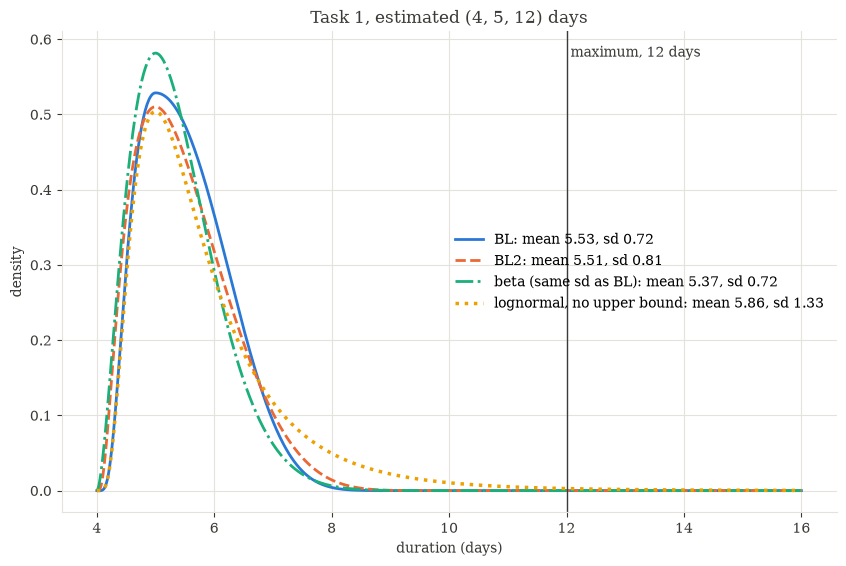

In [4]:
def beta_same_sd(lo, ml, hi, sd):
    """Beta on [lo, hi] with mode ml and standard deviation sd."""
    w = (ml - lo) / (hi - lo)
    def sd_gap(kappa):            # alpha = 1 + w kappa, beta = 1 + (1 - w) kappa
        return stats.beta(1 + w * kappa, 1 + (1 - w) * kappa,
                          loc=lo, scale=hi - lo).std() - sd
    kappa = brentq(sd_gap, 1e-6, 1e6)
    return stats.beta(1 + w * kappa, 1 + (1 - w) * kappa, loc=lo, scale=hi - lo)


def lognormal_from_min(lo, ml, sigma):
    """Lognormal on (lo, inf) with mode ml and standard deviation sigma.
    With t = shape^2: mode = exp(mu - t) and var = (e^t - 1) e^(2 mu + t),
    so (e^t - 1) e^(3t) = (sigma / (ml - lo))^2."""
    m = ml - lo
    t = brentq(lambda t: np.expm1(t) * np.exp(3 * t) - (sigma / m) ** 2, 1e-12, 50)
    return stats.lognorm(np.sqrt(t), loc=lo, scale=m * np.exp(t))


def task_dists(lo, ml, hi, sigma):
    rv_BL = bl.from_bounds(ml, sigma, lo, hi)
    return {'BL': rv_BL,
            'BL2': bl2.from_bounds(ml, sigma, lo, hi),
            'beta (same sd as BL)': beta_same_sd(lo, ml, hi, rv_BL.std()),
            'lognormal, no upper bound': lognormal_from_min(lo, ml, sigma)}


DISTS = [task_dists(*t, s) for t, s in zip(TASKS, SIGMA)]

lo, ml, hi = TASKS[0]
x = np.linspace(lo, hi + 4, 801)
fig, ax = plt.subplots()
for name, rv in DISTS[0].items():
    ax.plot(x, rv.pdf(x), label=f"{name}: mean {rv.mean():.2f}, sd {rv.std():.2f}",
            **STYLE[name])
ax.axvline(hi, color=INK, lw=1)
ax.annotate(f' maximum, {hi} days', (hi, 0.97), xycoords=('data', 'axes fraction'),
            color=INK, va='top')
ax.set_title(f'Task 1, estimated ({lo}, {ml}, {hi}) days', color=INK)
ax.set_xlabel('duration (days)'); ax.set_ylabel('density')
ax.legend(frameon=False)
plt.show()

Now the roll-up: draw every task independently, add them up, and read off the percentiles a schedule is planned on.

In [5]:
def simulate(name, seed=1):
    rng = np.random.default_rng(seed)
    return sum(d[name].rvs(size=N, random_state=rng) for d in DISTS)


TOTAL_MAX = sum(t[2] for t in TASKS)
DEADLINE = 60
totals = {name: simulate(name) for name in STYLE}

for name, t in totals.items():
    p50, p80, p95, p99 = np.percentile(t, [50, 80, 95, 99])
    print(f"{name:<21} P50 {p50:5.1f}  P80 {p80:5.1f}  P95 {p95:5.1f}  P99 {p99:5.1f} days; "
          f"P(over {DEADLINE} days) {np.mean(t > DEADLINE):.4f}; "
          f"P(over {TOTAL_MAX}, the sum of the maximums) {np.mean(t > TOTAL_MAX):.1e}; "
          f"longest draw {t.max():.0f}")

BL                    P50  53.0  P80  55.2  P95  57.4  P99  59.3 days; P(over 60 days) 0.0048; P(over 114, the sum of the maximums) 0.0e+00; longest draw 65
BL2                   P50  52.7  P80  55.2  P95  57.7  P99  59.9 days; P(over 60 days) 0.0091; P(over 114, the sum of the maximums) 0.0e+00; longest draw 66
beta (same sd as BL)  P50  51.4  P80  53.7  P95  56.0  P99  58.0 days; P(over 60 days) 0.0017; P(over 114, the sum of the maximums) 0.0e+00; longest draw 65
lognormal, no upper bound P50  55.3  P80  59.4  P95  64.5  P99  70.3 days; P(over 60 days) 0.1727; P(over 114, the sum of the maximums) 5.0e-06; longest draw 128


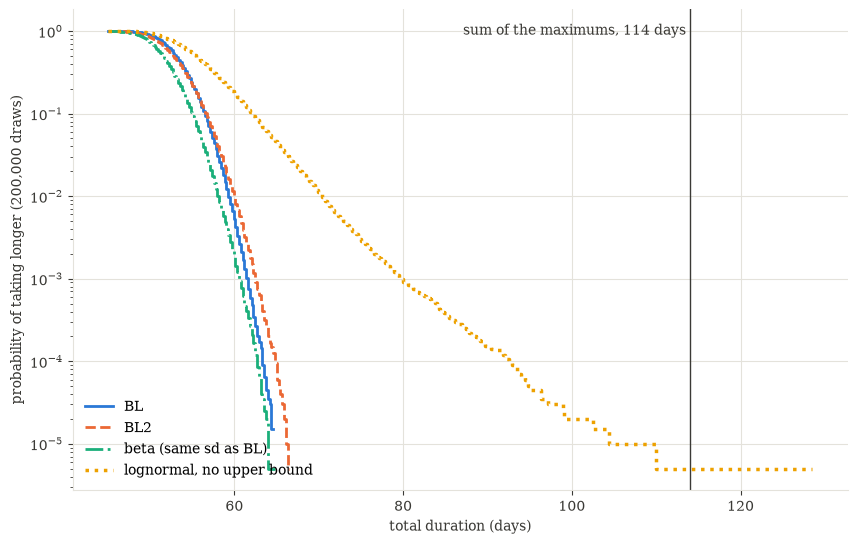

In [6]:
fig, ax = plt.subplots()
grid = np.linspace(45, 130, 400)
for name, t in totals.items():
    s = np.sort(t)
    sf = 1 - np.searchsorted(s, grid, side='right') / s.size
    ax.step(grid, np.where(sf > 0, sf, np.nan), where='post', label=name, **STYLE[name])
ax.axvline(TOTAL_MAX, color=INK, lw=1)
ax.annotate(f'sum of the maximums, {TOTAL_MAX} days ', (TOTAL_MAX, 0.97),
            xycoords=('data', 'axes fraction'), color=INK, va='top', ha='right')
ax.set_yscale('log')
ax.set_xlabel('total duration (days)')
ax.set_ylabel(f'probability of taking longer ({N:,} draws)')
ax.legend(frameon=False, loc='lower left')
plt.show()

**Where the bounded form matters: everywhere, not just at the extreme.** Without the upper bound, the same model puts some probability on totals no task list allows, longer than every task taking its maximum at once (a few draws in a million here, the longest well past the sum of the maximums). More important in practice, it moves every planning percentile later: P80 is about 4 days later, and the chance of missing a 60-day deadline goes from about 0.5% to about 17%. Each task keeps its full spread instead of having its long tail cut off at the maximum, and eight such tails add up.

**Where BL vs BL2 hardly matters.** The two families give the same P80 and agree within 0.3 days up to P95. Summing eight independent tasks averages away most of the difference in shape between them (the central limit theorem at work). They part further out, where a roll-up rarely plans: the chance of running past 60 days is about 0.5% under BL and 0.9% under BL2. For the usual planning percentiles, with the same estimates and the same sigma convention, either family serves.

**The shape matters more than the family.** The beta with the same minimum, most likely, maximum *and standard deviation* as BL has a lower mean, and gives a schedule about 1.5 days earlier at P80. So "the same three points" does not pin down a distribution, nor does adding a standard deviation; the shape is a modelling choice, and here it moves the answer by more than BL vs BL2 does.

### Why Monte Carlo results from the notebook-era BL must be re-run

The notebook-era BL's `rvs` returned its draws grouped by side of the mode: all the draws below the mode first, then all those above. A simulation that adds several such variables draw by draw then pairs short durations with short ones and long with long, as if the tasks were strongly correlated. The package returns draws in generated order. Below, the old behaviour is emulated by regrouping the package's own draws, which reproduces the old output order exactly.

In [7]:
def simulate_grouped(seed=1):
    rng = np.random.default_rng(seed)
    total = np.zeros(N)
    for (lo, ml, hi), d in zip(TASKS, DISTS):
        x = d['BL'].rvs(size=N, random_state=rng)
        total += np.r_[x[x <= ml], x[x > ml]]     # the notebook-era output order
    return total


rng = np.random.default_rng(7)
a, b = (d['BL'].rvs(size=N, random_state=rng) for d in DISTS[:2])
grouped = lambda x, ml: np.r_[x[x <= ml], x[x > ml]]
print(f"BL  correlation between tasks 1 and 2, drawn independently: "
      f"{np.corrcoef(a, b)[0, 1]:+.3f} now, "
      f"{np.corrcoef(grouped(a, TASKS[0][1]), grouped(b, TASKS[1][1]))[0, 1]:+.3f} "
      f"with notebook-era ordering")

old = simulate_grouped()
new = totals['BL']
for label_, t in (('BL, package (correct)', new), ('BL, notebook-era ordering', old)):
    print(f"{label_:<26} mean {t.mean():5.2f}  sd {t.std():4.2f}  "
          f"P80 {np.percentile(t, 80):5.1f}  P95 {np.percentile(t, 95):5.1f} days; "
          f"P(over {DEADLINE} days) {np.mean(t > DEADLINE):.4f}")

BL  correlation between tasks 1 and 2, drawn independently: +0.002 now, +0.369 with notebook-era ordering
BL, package (correct)      mean 53.09  sd 2.50  P80  55.2  P95  57.4 days; P(over 60 days) 0.0048
BL, notebook-era ordering  mean 53.09  sd 4.72  P80  56.9  P95  59.0 days; P(over 60 days) 0.0219


Same mean, but the old ordering nearly doubles the spread of the total and inflates its tail percentiles and its chance of missing the deadline. Any earlier Monte Carlo result that combined several notebook-era BL variables draw by draw should be re-run with the package, not reused.

## B. One input with its most likely value near a bound

Now a single uncertain input that drives a decision: the fraction of the work that has to be redone. It lies between 0% and 40%, is most likely about 2%, and has a long right tail. With the most likely value this close to the lower bound, BL and BL2 differ most (the README notes CDF gaps up to about 0.26).

The question: what is the chance that rework exceeds 10%, the level that triggers a contingency budget?

### Same parameters

Suppose the parameters are elicited directly: most likely 2%, sigma 5 percentage points, bounds 0% and 40%.

BL  mode 2%, sigma 5 points: P(rework > 10%) 0.044, 95th percentile 9.8%, mean 4.69%
BL2 mode 2%, sigma 5 points: P(rework > 10%) 0.056, 95th percentile 10.3%, mean 4.45%
largest CDF difference between them: 0.062 at 3.4%
most likely 0.40%: largest CDF difference 0.152; P(rework > 10%) BL 0.018, BL2 0.023


most likely 0.04%: largest CDF difference 0.262; P(rework > 10%) BL 0.015, BL2 0.015


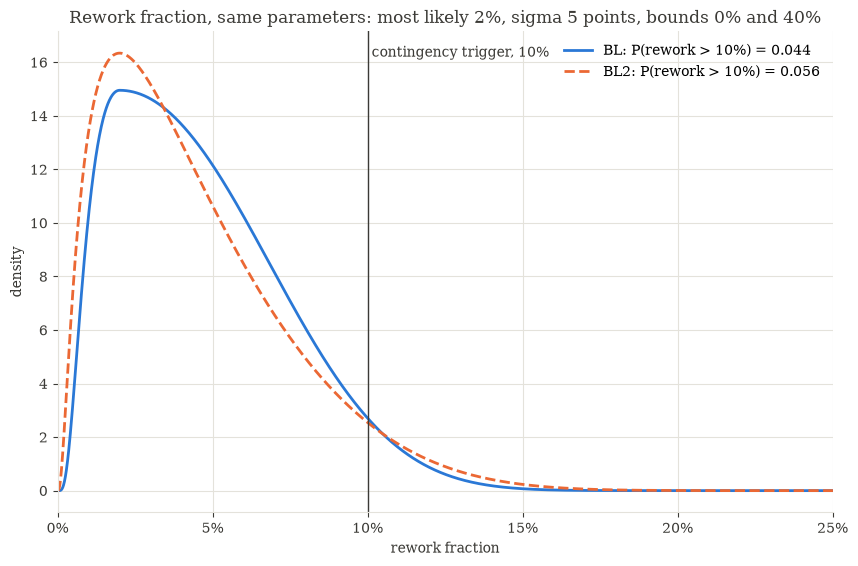

In [8]:
y = np.linspace(0, 0.4, 4001)[1:-1]
same = {'BL': bl.from_bounds(0.02, 0.05, 0, 0.4),
        'BL2': bl2.from_bounds(0.02, 0.05, 0, 0.4)}
for name, rv in same.items():
    print(f"{name:<3} mode 2%, sigma 5 points: P(rework > 10%) {rv.sf(0.10):.3f}, "
          f"95th percentile {rv.ppf(0.95):.1%}, mean {rv.mean():.2%}")
gap = np.abs(same['BL'].cdf(y) - same['BL2'].cdf(y))
print(f"largest CDF difference between them: {gap.max():.3f} at {y[gap.argmax()]:.1%}")

for mode in (0.004, 0.0004):
    rvs_ = {fam: d.from_bounds(mode, 0.05, 0, 0.4) for fam, d in (('BL', bl), ('BL2', bl2))}
    g = np.abs(rvs_['BL'].cdf(y) - rvs_['BL2'].cdf(y)).max()
    print(f"most likely {mode:.2%}: largest CDF difference {g:.3f}; P(rework > 10%) "
          f"BL {rvs_['BL'].sf(0.10):.3f}, BL2 {rvs_['BL2'].sf(0.10):.3f}")

fig, ax = plt.subplots()
for name, rv in same.items():
    ax.plot(y, rv.pdf(y), label=f"{name}: P(rework > 10%) = {rv.sf(0.10):.3f}", **STYLE[name])
ax.axvline(0.10, color=INK, lw=1)
ax.annotate(' contingency trigger, 10%', (0.10, 0.97), xycoords=('data', 'axes fraction'),
            color=INK, va='top')
ax.set_xlim(0, 0.25)
ax.set_title('Rework fraction, same parameters: most likely 2%, sigma 5 points, '
             'bounds 0% and 40%', color=INK)
ax.set_xlabel('rework fraction'); ax.set_ylabel('density')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.legend(frameon=False)
plt.show()

With the same elicited parameters the two families disagree about the decision: the chance of triggering the contingency is about a quarter higher under BL2 than under BL. As the most likely value moves closer to the bound, the largest difference between their CDFs grows (0.06, 0.15, 0.26 above). That difference sits near the most likely value, though, so how much it moves a particular decision depends on where the decision's threshold lies; at the 10% trigger it happens to shrink. **The parameters are not portable between the families:** a (mode, sigma) chosen with one in mind means something different in the other. Pick a family and stay with it.

### Fitted to the same data

Usually there are data, say the rework fractions of 30 past projects. Each family is then fitted to those data separately. Here the data are drawn from a third distribution (a scaled beta, most likely about 1.9%), so neither family is the truth. The bounds are known (0% and 40%) and held fixed; the mode and sigma are fitted by maximum likelihood.

In [9]:
truth = stats.beta(1.5, 11, loc=0, scale=0.4)
print(f"truth: P(rework > 10%) {truth.sf(0.10):.3f}")

past = truth.rvs(size=30, random_state=np.random.default_rng(0))
fitted = {}
for name, dist in (('BL', bl), ('BL2', bl2)):
    f = dist.fit_bounds(past, 'MLE', flower=0, fupper=0.4)
    fitted[name] = dist.from_bounds(*f)
    print(f"{name:<3} fitted to the 30 projects: mode {f.mode:.2%}, sigma {f.sigma:.2%}; "
          f"P(rework > 10%) {fitted[name].sf(0.10):.3f} (fit identified: {f.success})")

truth: P(rework > 10%) 0.091
BL  fitted to the 30 projects: mode 0.30%, sigma 5.67%; P(rework > 10%) 0.033 (fit identified: True)


BL2 fitted to the 30 projects: mode 1.61%, sigma 4.80%; P(rework > 10%) 0.041 (fit identified: True)


The two families land on quite different parameters, because they are different distributions, but on similar answers to the question. That is the practical point: fit the family you use to the data, rather than carrying parameters over.

Both answers here are far from the truth's. With 30 projects, the sampling noise is large. Repeating the exercise on many independent sets of 30 shows how the family difference compares with that noise:

In [10]:
d_family, err = [], {'BL': [], 'BL2': []}
for seed in range(1, REPEATS + 1):
    data = truth.rvs(size=30, random_state=np.random.default_rng(seed))
    p = {}
    for name, dist in (('BL', bl), ('BL2', bl2)):
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', RuntimeWarning)
            p[name] = dist.from_bounds(*dist.fit_bounds(data, 'MLE', flower=0,
                                                        fupper=0.4)).sf(0.10)
        err[name].append(p[name] - truth.sf(0.10))
    d_family.append(p['BL'] - p['BL2'])
d_family = np.array(d_family)
print(f"over {REPEATS} sets of 30 projects, P(rework > 10%):")
for name in err:
    e = np.array(err[name])
    print(f"  {name:<3} fitted minus truth: median {np.median(e):+.3f}, "
          f"middle 90% {np.percentile(e, 5):+.3f} to {np.percentile(e, 95):+.3f}")
print(f"  BL minus BL2, same data:  median {np.median(d_family):+.3f}, "
      f"middle 90% {np.percentile(d_family, 5):+.3f} to {np.percentile(d_family, 95):+.3f}")

over 100 sets of 30 projects, P(rework > 10%):
  BL  fitted minus truth: median -0.017, middle 90% -0.067 to +0.093
  BL2 fitted minus truth: median -0.007, middle 90% -0.058 to +0.079
  BL minus BL2, same data:  median -0.004, middle 90% -0.015 to +0.016


Fitted to the same data, the two families usually agree on the decision to within a percentage point or two, far closer than the elicited-parameter case above. The sampling error from having only 30 projects is several times larger. Occasionally the families still disagree by more, so with little data it is worth checking the answer under both.

## Summary

- **The bounded form matters,** and not only in the extreme tail. Without the bound the same model allows totals no task list allows, and it moves every planning percentile later (here P80 by about 4 days, and the chance of missing the deadline from 0.5% to 17%).
- **BL vs BL2 hardly matters for a sum** of several independent tasks with the same estimates: the planning percentiles agree within 0.3 days up to P95. Far out in the tail they part (a 0.5% vs 0.9% chance of passing 60 days).
- **The shape matters more than the family.** A beta with the same three points and the same standard deviation as BL gives a schedule about 1.5 days earlier at P80.
- **BL vs BL2 does matter for a single input with its mode near a bound,** when both are given the same parameters. The parameters are not portable between the families.
- **Fitted to the same data,** the two families give similar answers to the decision question, and the sampling uncertainty dominates. Always report which family a number came from.
- **Re-run old simulations.** The notebook-era BL returned draws grouped by side of the mode, which nearly doubles the spread of a sum. Results built from several such variables should be re-run.